---
## Trabalho Prático I - Individual
## Data de entrega: 04/09/2024
---

O objetivo desse Trabalho Prático 1 é aplicar filtros em uma dada imagem tanto no domínio **espacial** quanto no domínio da **frequência**. Sabe-se que filtragem aplicada a uma imagem digital é uma operação local que modifica os valores de cada intensidade dos pixels da imagem.
Durante o procedimento de filtragem, utiliza-se uma operação de convolução, onde uma máscara é aplicada à imagem. Esse processo envolve percorrer toda a imagem e ajustar seus valores de acordo com os pesos da máscara e as intensidades da imagem.


## 1- Filtragem no Domínio Espacial

A filtragem no domínio espacial refere-se a uma abordagem de processamento de imagens na qual as operações são aplicadas diretamente aos pixels da imagem original, considerando sua posição espacial. Em outras palavras, os filtros são aplicados aos valores de intensidade dos pixels na própria imagem, sem transformações adicionais.

**1.1 Exemplos de Filtros no Domínio Espacial**

$$ h_1=
\begin{bmatrix}
0 & -1 & 0  \\
1 & -4 & 1  \\
0 & 1 & 0  \\
\end{bmatrix} (Filtro\_Laplaciano)
$$

\\
$$ h_2=
\begin{bmatrix}
0 & 0 & -1 & 0 & 0 \\
0 & -1 & -2 & -1 & 0 \\
-1 & -2 & 16 & -2 & -1 \\
0 & -1 & -2 & -1 & 0 \\
0 & 0 & -1 & 0 & 0 \\
\end{bmatrix}
$$

\\
$$ h_3= 1/256
\begin{bmatrix}
1 & 4 & 6 & 4 & 1 \\
4 & 16 & 24 & 16 & 4 \\
6 & 24 & 36 & 24 & 6 \\
4 & 16 & 24 & 16 & 4 \\
1 & 4 & 6 & 4 & 1 \\
\end{bmatrix}
$$

\\
$$ h_4=
\begin{bmatrix}
-1 & 0 & 1  \\
-2 & 0 & 2  \\
-1 & 0 & 1  \\
\end{bmatrix}
$$


In [1]:
import numpy as np

H1 = np.array([[0, -1, 0],
              [-1, 4, -1],
              [0, -1, 0]
               ])

H2 = np.array([[0, 0, -1, 0, 0],
               [0, -1, -2, -1, 0],
               [-1, -2, 16, -2, -1],
               [0, -1, -2, -1, 0],
               [0, 0, -1, 0, 0]])

H3 = (1 / 256) * np.array([[1, 4, 6, 4, 1],
                           [4, 16, 24, 16, 4],
                           [6, 24, 36, 24, 6],
                           [4, 16, 24, 16, 4],
                           [1, 4, 6, 4, 1]])

H4 = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]])


**1.2 Filtragem Laplaciana**

A filtragem Laplaciana, também conhecida como operador Laplaciano, é uma técnica de processamento de imagens usada para detectar áreas de mudanças abruptas na intensidade dos pixels de uma imagem. Ela é comumente usada para realçar bordas e detalhes de alta frequência em uma imagem. Um exemplo de implementação usando a função **cv2.filter2D(image, -1, kernel)**.

Aplique cada um dos filtros a seguir em uma imagem e explique os efeitos de cada um deles. Isto é troque, o kernel da *função laplacian_filter*.

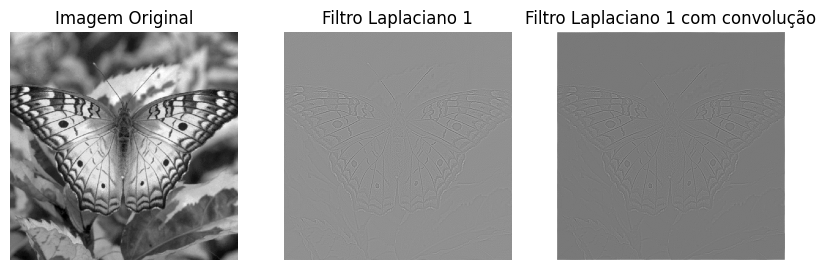

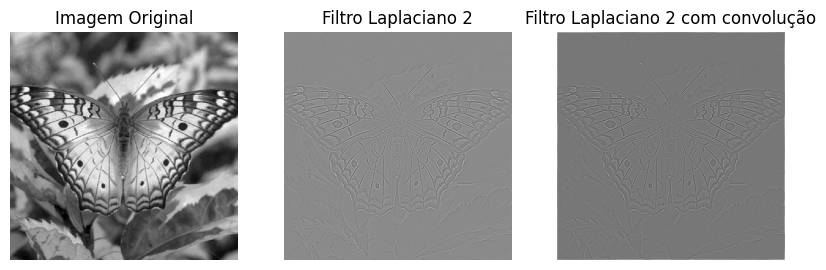

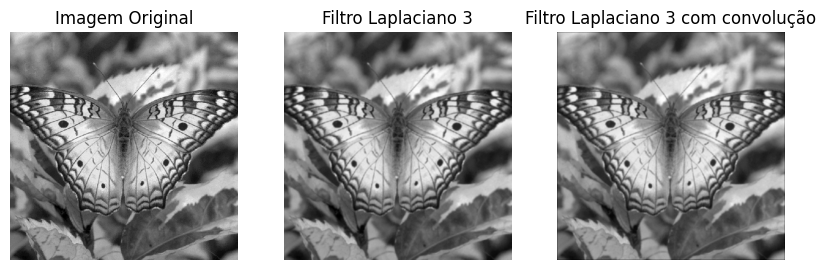

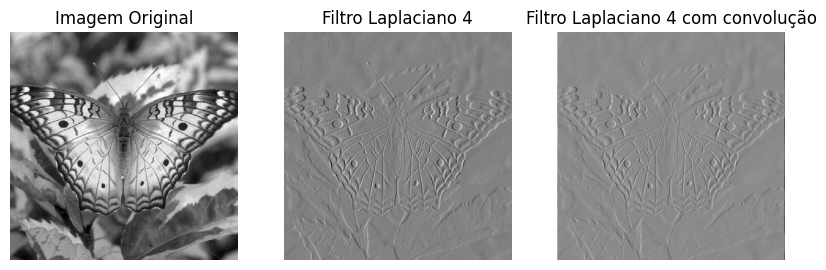

In [2]:
import cv2
import matplotlib.pyplot as plt

# Implemente a função convolve


def convolve(image, kernel):
    # Inicialização da matriz de convolução
    convolved_image = np.zeros_like(image)

    # Inicialização das dimensões da imagem e do kernel
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # Inicialização do padding
    pad_height = kernel_height // 2
    pad_width = kernel_width // 2

    # Aplicação do padding na imagem
    padded_image = np.zeros(
        (image_height + (2 * pad_height), image_width + (2 * pad_width)))
    padded_image[pad_height:padded_image.shape[0] - pad_height,
                 pad_width:padded_image.shape[1] - pad_width] = image

    # Aplicação do kernel na imagem
    for i in range(image_height):
        for j in range(image_width):
            convolved_image[i, j] = np.sum(
                kernel * padded_image[i:i + kernel_height, j:j + kernel_width])

    return convolved_image


def laplacian_filter(image, kernel):

    # Aplicação do filtro Laplaciano com auxílio da biblioteca cv2
    filtered_image = cv2.filter2D(image, -1, kernel)

    # Aplicação da convolução por meio da chamada da função convolve
    filtered_image_with_convolve = convolve(image, kernel)

    return filtered_image, filtered_image_with_convolve


image = plt.imread('./butterfly.png')

if image is None:
    print("Erro ao ler a imagem.")
    exit()

# Aplicar o filtro Laplaciano na imagem
filtered_image_1, filtered_image_with_convolve_1 = laplacian_filter(image, H1)
filtered_image_2, filtered_image_with_convolve_2 = laplacian_filter(image, H2)
filtered_image_3, filtered_image_with_convolve_3 = laplacian_filter(image, H3)
filtered_image_4, filtered_image_with_convolve_4 = laplacian_filter(image, H4)

# Plotar a imagem original e a imagem filtrada


def plot_image(image, filtered_image, filtered_image_with_convolve, title):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap='gray')
    plt.title('Imagem Original')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(filtered_image, cmap='gray')
    plt.title(f'{title}')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(filtered_image_with_convolve, cmap='gray')
    plt.title(f'{title} com convolução')
    plt.axis('off')

    plt.show()


plot_image(image, filtered_image_1,
           filtered_image_with_convolve_1, 'Filtro Laplaciano 1')
plot_image(image, filtered_image_2,
           filtered_image_with_convolve_2, 'Filtro Laplaciano 2')
plot_image(image, filtered_image_3,
           filtered_image_with_convolve_3, 'Filtro Laplaciano 3')
plot_image(image, filtered_image_4,
           filtered_image_with_convolve_4, 'Filtro Laplaciano 4')


**1.3 Implemente a Função Convolve**

Façam testes utlizando a implementação da Filtragem Laplaciana

**1.4 Exemplo de Combinação de Filtros**

Este exemplo é apenas uma demonstração que podemos utilizar mais de um filtro numa mesma imagem.



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1010981..1.8872156].


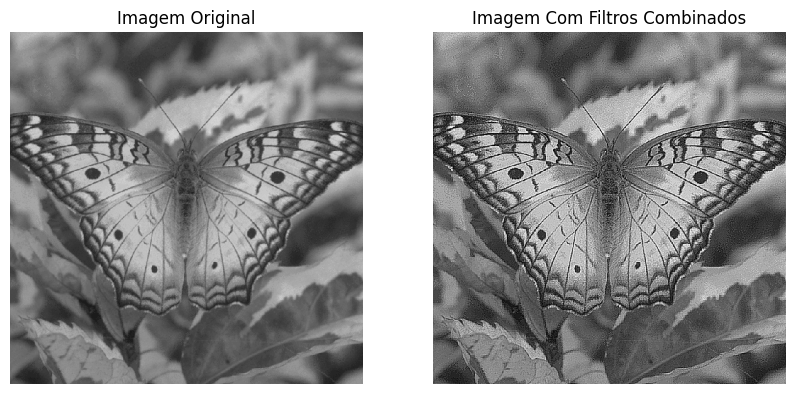

In [3]:
imagem = plt.imread('./butterfly.png')

# Verificar se a leitura da imagem foi bem-sucedida
if imagem is None:
    print("Erro ao ler a imagem.")
    exit()

# Aplicar filtro de suavização (filtro de média)
filtro_suavizacao = cv2.blur(imagem, (5, 5))

# Aplicar filtro de nitidez
filtro_nitidez = cv2.filter2D(imagem, -1, np.array([[-1, -1, -1],
                                                    [-1, 9, -1],
                                                    [-1, -1, -1]]))

# Combinar os resultados dos filtros
imagem_combinada = cv2.addWeighted(
    filtro_suavizacao, 0.5, filtro_nitidez, 0.5, 0)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
plt.title('Imagem Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(imagem_combinada, cv2.COLOR_BGR2RGB))
plt.title('Imagem Com Filtros Combinados')
plt.axis('off')

plt.show()


**1.5 Implemente outros exemplos de combinação de Filtros Espaciais utilizando os filtros do Item 1.1**

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9137255..2.1117647].


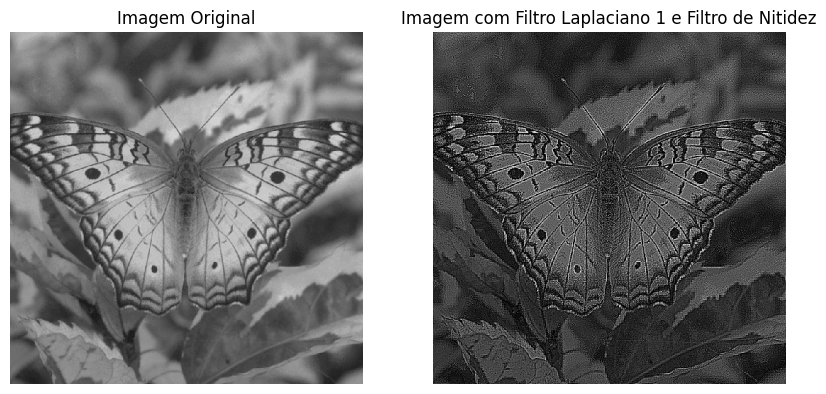

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.062745..3.9215682].


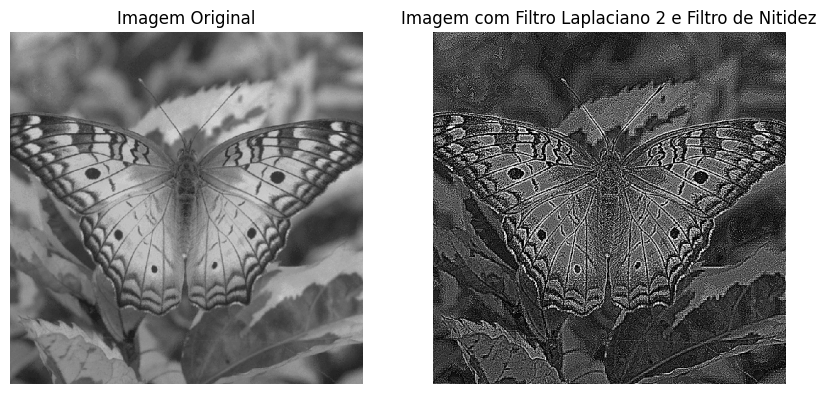

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1519377..1.9302082].


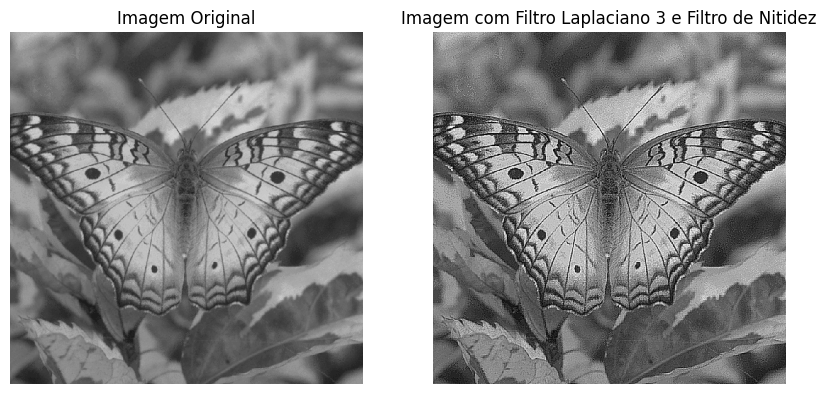

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0392158..2.2921567].


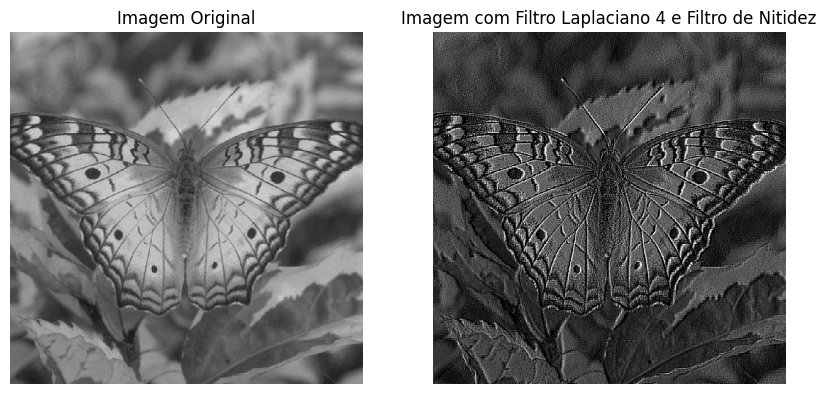

In [4]:
# Combinar os resultados dos filtros
def apply_filter(kernel, title):
    kernel = cv2.filter2D(imagem, -1, kernel)
    imagem_combinada = cv2.addWeighted(
        kernel, 0.5, filtro_nitidez, 0.5, 0)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
    plt.title('Imagem Original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(imagem_combinada, cv2.COLOR_BGR2RGB))
    plt.title(f'Imagem com {title} e Filtro de Nitidez')
    plt.axis('off')

    plt.show()


apply_filter(H1, 'Filtro Laplaciano 1')
apply_filter(H2, 'Filtro Laplaciano 2')
apply_filter(H3, 'Filtro Laplaciano 3')
apply_filter(H4, 'Filtro Laplaciano 4')


## 2 - Filtragem no Domínio da Frequência

Filtragem no domínio da frequência é uma técnica utilizada em processamento de imagens para realizar operações de filtragem em imagens através de Transformada de Fourier. Nesta técnica, em vez de operar diretamente nos pixels da imagem no domínio espacial, as operações de filtragem são realizadas no domínio da frequência após a imagem ter sido transformada usando a Transformada de Fourier.

A ideia principal é que a Transformada de Fourier de uma imagem a transforma do domínio espacial (onde a informação está representada em termos de intensidades de pixel) para o domínio da frequência (onde a informação está representada em termos de componentes de frequência). Nesse domínio, as características da imagem, como bordas e padrões, podem ser interpretadas de maneira diferente e, portanto, manipuladas de maneira eficaz.

Exemplo de Transformada de Fourier, onde a componente de frequência-zero foi  transladada para o centro do espectro (observe o ponto central da imagem resultante).

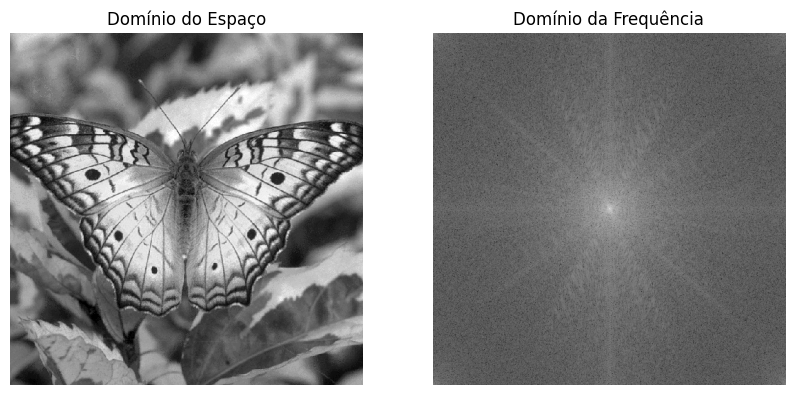

In [5]:
image = cv2.imread('./butterfly.png', cv2.IMREAD_GRAYSCALE)

# Aplicar a Transformada de Fourier
fourier_transform = np.fft.fft2(image)
# Realiza a translação da origem do espectro para o centro da imagem
fourier_transform_shifted = np.fft.fftshift(fourier_transform)
# Obtém o espectro de magnitude (magnitude das componentes de frequência)
magnitude_spectrum = 20 * np.log(np.abs(fourier_transform_shifted))

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Domínio do Espaço')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Domínio da Frequência')
plt.axis('off')

plt.show()


**2.1 Filtro Gaussiano**

Um filtro Gaussiano em processamento de imagens é um tipo de filtro passa-baixa. Ele permite passar as frequências mais baixas (componentes de baixa frequência) enquanto atenua as frequências mais altas (componentes de alta frequência). Isso significa que o filtro gaussiano suaviza a imagem, reduzindo o ruído de alta frequência e preservando as características de baixa frequência, como bordas e grandes áreas de transição de intensidade. Portanto, o filtro gaussiano é comumente usado para suavizar ou "borrar" uma imagem, tornando-a mais homogênea e removendo detalhes finos.

Um exemplo de implementação do Filtro Gaussiano.

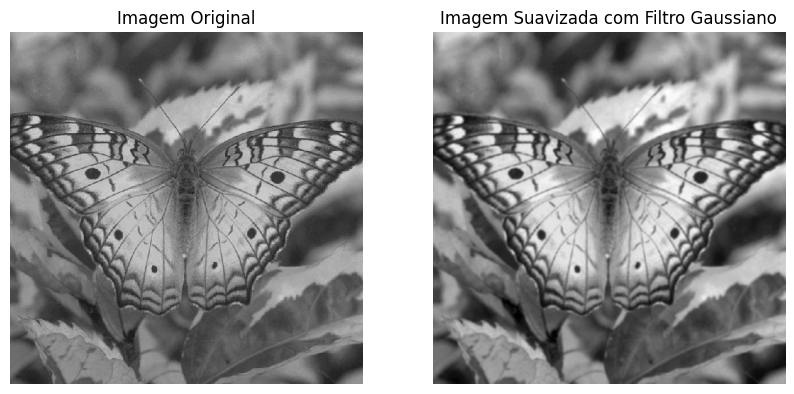

In [6]:
image = cv2.imread('./butterfly.png', cv2.IMREAD_GRAYSCALE)

# Aplicar o filtro gaussiano
# Usando um kernel de tamanho 5x5
# Terceiro parâmetro '0' indica que o desvio padrão do filtro é
# Calculado automaticamente com base no tamanho do kernel.
imagem_suavizada = cv2.GaussianBlur(image, (5, 5), 0)

# Plotar a imagem original e a imagem suavizada
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Imagem Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagem_suavizada, cmap='gray')
plt.title('Imagem Suavizada com Filtro Gaussiano')
plt.axis('off')

plt.show()


**2.2 Grau de Suavização para Filtros Gaussianos**

O grau de suavização no filtro gaussiano se refere à intensidade ou magnitude da suavização aplicada à imagem. Esse grau é controlado principalmente pelo tamanho do kernel e pelo desvio padrão do filtro gaussiano.



1.   **Tamanho do Kernel**: Determina a área da vizinhança considerada ao calcular a média ponderada dos pixels. Um kernel maior significa que uma área maior ao redor de cada pixel está sendo considerada, resultando em uma suavização mais forte. Por exemplo, um kernel de 5x5 suavizará mais a imagem do que um kernel de 3x3.
2.   **Desvio Padrão**: Controla a largura da distribuição gaussiana. Um desvio padrão maior resulta em uma distribuição mais larga, o que significa que a suavização é mais suave e gradual. Por outro lado, um desvio padrão menor resulta em uma distribuição mais estreita, o que significa que a suavização é mais agressiva.



Aplique um filtro Gaussiano em uma imagem representada por seu espectro de Fourier. A componente de frequência-zero deve ser transladada para o centro do espectro. Experimente diferentes graus de suavização, de forma a borrar a imagem com mais ou menos intensidade.


1.   Kernel 3x3 com desvio padrão baixo;
2.   Kernel 5x5 com desvio padrão médio;
3.   Kernel 7x7 com desvio padrão alto.





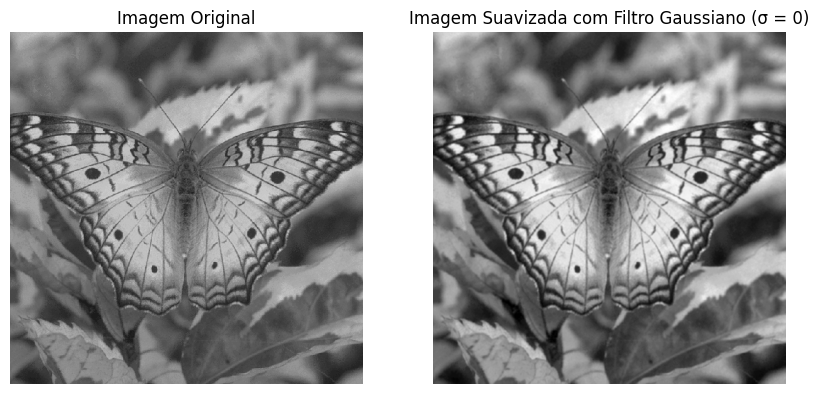

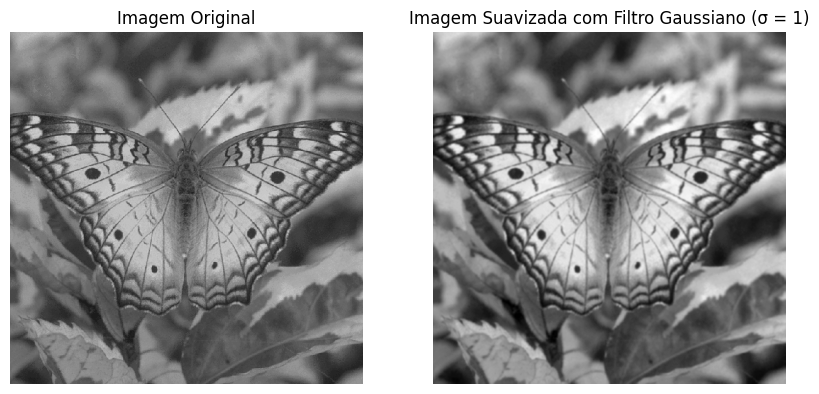

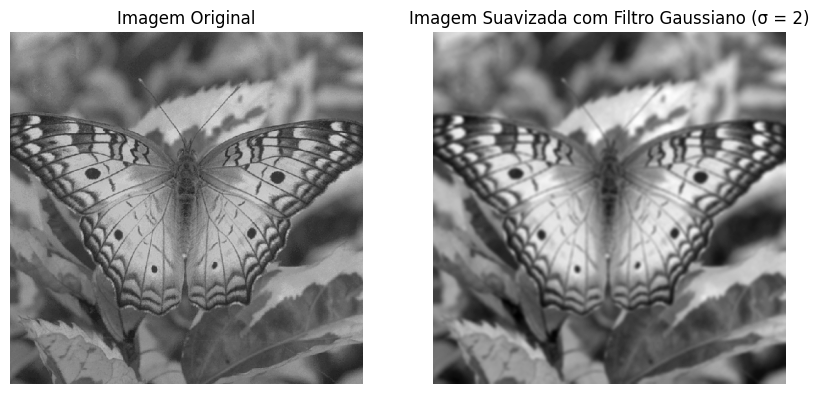

In [7]:
def apply_gaussian_filter(kernel_size, sigma):
    imagem_suavizada = cv2.GaussianBlur(image, kernel_size, sigma)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title('Imagem Original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(imagem_suavizada, cmap='gray')
    plt.title(f'Imagem Suavizada com Filtro Gaussiano (σ = {sigma})')
    plt.axis('off')

    plt.show()


apply_gaussian_filter((3, 3), 0)
apply_gaussian_filter((5, 5), 1)
apply_gaussian_filter((7, 7), 2)
